<a href="https://colab.research.google.com/github/xabierblanch/EGG_FotogrametriaTerrestre/blob/main/FMT_S6_POSE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LA POSE D'UNA CÀMERA - Exercicis pràctics

La **pose** d'una càmera són els 6 paràmetres externs: on és el seu centre òptic $(X_0, Y_0, Z_0)$ i cap on mira (el gir $R$). En aquest notebook la calculem pels **dos camins** de la teoria:

Les dues equacions que farem servir:

$$\text{Col·linealitat:}\quad \lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \, R \begin{bmatrix} X - X_0 \\ Y - Y_0 \\ Z - Z_0 \end{bmatrix} \qquad\qquad \text{Coplanarietat:}\quad \mathbf{x}_B^T \, E \, \mathbf{x}_A = 0, \quad E = [\mathbf{t}]_\times R$$

## 0.- Configuració de l'entorn

Importem les llibreries i definim les funcions de dibuix 3D que farem servir a tot el notebook.

**Conveni d'eixos de la càmera (OpenCV):** $x$ cap a la dreta de la foto, $y$ cap avall i $z$ endavant (cap on mira la càmera). Una pose ve donada per la matriu de rotació $R$ (gira els eixos del món als de la càmera) i pel centre òptic $\mathbf{X}_0$:

$$\mathbf{X}_{càmera} = R \, (\mathbf{X} - \mathbf{X}_0)$$

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

plt.rcParams['figure.dpi'] = 90
np.set_printoptions(precision=4, suppress=True)
RANDOM_SEED = 0
CAMERA_COLORS = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e']


def load_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)


def camera_center(R, t):
    """OpenCV gives X_cam = R·X + t. The optical centre in world coordinates is X0 = -Rᵀ·t."""
    return (-R.T @ np.asarray(t).reshape(3)).ravel()


def rotation_angle_deg(R):
    """Total rotation angle of a rotation matrix (length of its rvec), in degrees."""
    return float(np.degrees(np.linalg.norm(cv2.Rodrigues(R)[0])))


def camera_traces(R, center, color, name, size=80.0, to_display=lambda p: p, label=True, legend=True):
    """Plotly traces of a camera: frustum (pyramid with the image plane) + optical axis.
    R rotates world -> camera, center is the optical centre in world coordinates."""
    w, h = 0.6 * size, 0.45 * size
    corners_cam = np.array([[-w, -h, size], [w, -h, size], [w, h, size], [-w, h, size]])
    corners = (R.T @ corners_cam.T).T + center
    axis_tip = center + R.T @ np.array([0, 0, 2.2 * size])
    c, k, a = to_display(center[None])[0], to_display(corners), to_display(axis_tip[None])[0]
    lines = []
    for p in k:
        lines += [c, p, [None] * 3]
    lines += [k[0], k[1], k[2], k[3], k[0], [None] * 3]
    lines = np.array(lines, dtype=object)
    return [
        go.Scatter3d(x=lines[:, 0], y=lines[:, 1], z=lines[:, 2], mode='lines', line=dict(color=color, width=4),
                     name=name, legendgroup=name, showlegend=legend),
        go.Mesh3d(x=k[:, 0], y=k[:, 1], z=k[:, 2], i=[0, 0], j=[1, 2], k=[2, 3], color=color, opacity=0.25,
                  legendgroup=name, showlegend=False, hoverinfo='skip'),
        go.Scatter3d(x=[c[0], a[0]], y=[c[1], a[1]], z=[c[2], a[2]], mode='lines', line=dict(color=color, width=2, dash='dash'),
                     legendgroup=name, showlegend=False, hoverinfo='skip'),
        go.Scatter3d(x=[c[0]], y=[c[1]], z=[c[2]], mode='markers+text' if label else 'markers', marker=dict(size=4, color=color),
                     text=[name], textposition='top center', legendgroup=name, showlegend=False, hovertext=name),
    ]


def show_3d(traces, title, height=650, eye=(1.4, -1.6, 1.0), axis_titles=('X (mm)', 'Y (mm)', 'Z (mm)')):
    fig = go.Figure(traces)
    fig.update_layout(title=title, height=height, margin=dict(l=0, r=0, t=40, b=0),
                      scene=dict(aspectmode='data', camera=dict(eye=dict(x=eye[0], y=eye[1], z=eye[2])),
                                 xaxis_title=axis_titles[0], yaxis_title=axis_titles[1], zaxis_title=axis_titles[2]))
    fig.show()


print("Entorn configurat correctament amb OpenCV", cv2.__version__)

Entorn configurat correctament amb OpenCV 4.14.0


# PART 1 — Camí 1: la pose a partir de punts coneguts

Al camí 1 coneixem les coordenades 3D d'uns quants punts de l'escena i sabem on surten a la foto. Els punts seran les **cantonades d'un tauler ChArUco**: com que sabem la mida de les caselles, sabem les coordenades de totes les cantonades en mil·límetres.



### 1.1.- Les fotos del tauler

Dues fotos del tauler ChArUco fetes des de dos llocs diferents: les càmeres **A** i **B**. Han d'estar fetes amb el mateix mòbil i en la mateixa orientació (vertical) que les fotos del calibratge, i sense zoom.

Falten aquests fitxers: ['tauler_A.jpg', 'tauler_B.jpg'] -> puja'ls ara


Saving tauler_A.jpg to tauler_A.jpg
Saving tauler_B.jpg to tauler_B.jpg


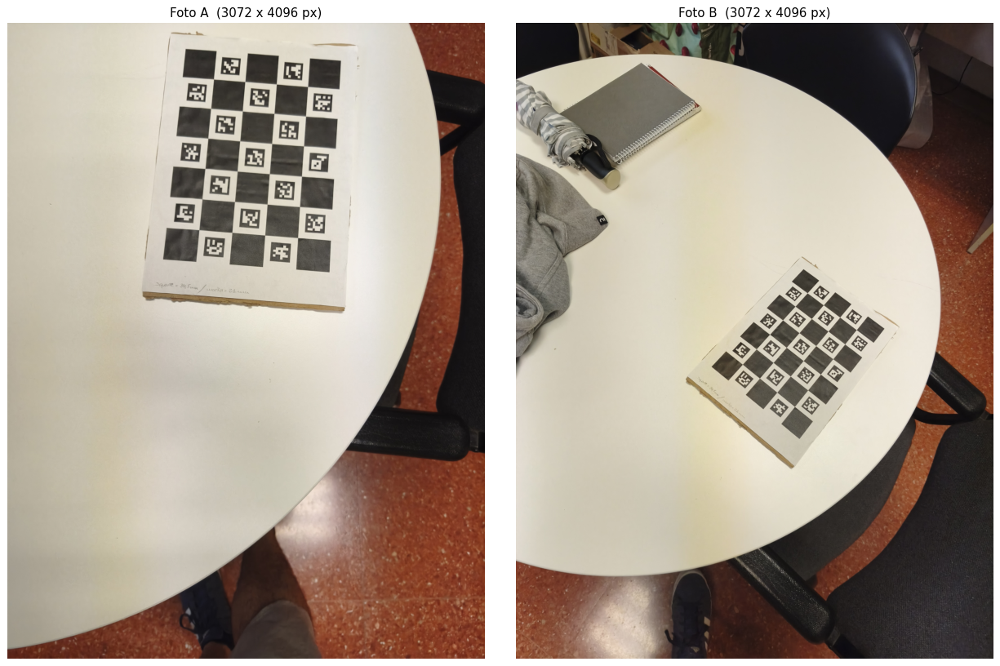

In [ ]:
TABLE_A_PATH, TABLE_B_PATH = 'tauler_A.jpg', 'tauler_B.jpg'

missing_files = [p for p in (TABLE_A_PATH, TABLE_B_PATH) if not os.path.exists(p)]
if missing_files and IN_COLAB:
    print("Falten aquests fitxers:", missing_files, "-> puja'ls ara")
    files.upload()

table_images = {'A': load_rgb(TABLE_A_PATH), 'B': load_rgb(TABLE_B_PATH)}

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, (name, image) in zip(axes, table_images.items()):
    ax.imshow(image)
    ax.set_title(f"Foto {name}  ({image.shape[1]} x {image.shape[0]} px)")
    ax.axis('off')
plt.tight_layout(); plt.show()

### 1.2.- El calibratge de la càmera: els paràmetres interns

Llegim el fitxer de calibratge `camera_calibration.xml`. Conté els **paràmetres interns** de la càmera:

$$K = \begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix} \qquad \mathbf{d} = (k_1, k_2, p_1, p_2, k_3)$$

* $f_x, f_y$: distància focal, en píxels.
* $c_x, c_y$: punt principal (on l'eix òptic talla la imatge), en píxels.
* $\mathbf{d}$: distorsió de la lent ($k$ radial, $p$ tangencial).

El fitxer també guarda la mida de les fotos amb què es va calibrar, l'error de reprojecció (RMS, en píxels; un bon calibratge dona menys d'1 px) i la pose de cada foto del calibratge (la farem servir a l'apartat 1.7).

In [ ]:
CALIBRATION_XML = 'camera_calibration.xml'

if not os.path.exists(CALIBRATION_XML) and IN_COLAB:
    print("Falta", CALIBRATION_XML, "-> puja'l ara")
    files.upload()

storage = cv2.FileStorage(CALIBRATION_XML, cv2.FILE_STORAGE_READ)
K = storage.getNode('camera_matrix').mat()
dist_coeffs = storage.getNode('dist_coeffs').mat().ravel()
calibration_size = (int(storage.getNode('image_width').real()), int(storage.getNode('image_height').real()))
calibration_rms = storage.getNode('rms').real()
calibration_rvecs, calibration_tvecs = storage.getNode('rvecs').mat(), storage.getNode('tvecs').mat()
storage.release()

print("K =\n", K.round(1))
print("\nd = (k1, k2, p1, p2, k3) =", dist_coeffs.round(4))
print(f"\nMida de les fotos del calibratge: {calibration_size[0]} x {calibration_size[1]} px   ·   error de reprojecció (RMS): {calibration_rms:.2f} px")
for name, image in table_images.items():
    same_size = (image.shape[1], image.shape[0]) == calibration_size
    print(f"Foto {name}: {'mateixa mida que el calibratge, OK' if same_size else 'ATENCIÓ: mida diferent de la del calibratge'}")

Falta camera_calibration.xml -> puja'l ara


Saving camera_calibration.xml to camera_calibration.xml
K =
 [[2763.5    0.  1574. ]
 [   0.  2750.3 2020.7]
 [   0.     0.     1. ]]

d = (k1, k2, p1, p2, k3) = [ 0.0085  0.1484 -0.0031  0.0021 -0.1872]

Mida de les fotos del calibratge: 3072 x 4096 px   ·   error de reprojecció (RMS): 0.86 px
Foto A: mateixa mida que el calibratge, OK
Foto B: mateixa mida que el calibratge, OK


### 1.3.- El tauler i el seu sistema de coordenades

El tauler té **5 × 7 caselles** de **34,5 mm**, i a les caselles blanques hi ha **marcadors ArUco** de **21 mm** (diccionari `DICT_6X6_250`). Cada marcador té un número (id) que OpenCV reconeix. Gràcies a això, OpenCV sap **quina** cantonada és cada una encara que només es vegi una part del tauler.

Les cantonades que es fan servir són les **interiors**, on es toquen quatre caselles: $4 \times 6 = 24$ cantonades.

**Triem el sistema de coordenades del món** (l'"origen" de la teoria):
* Origen: la cantonada exterior inferior esquerra del tauler.
* Eix $X$: al llarg de les 5 columnes. Eix $Y$: al llarg de les 7 files.
* Eix $Z$: perpendicular al tauler, **cap amunt**.
* Unitats: **mm**. Totes les cantonades tenen $Z = 0$.

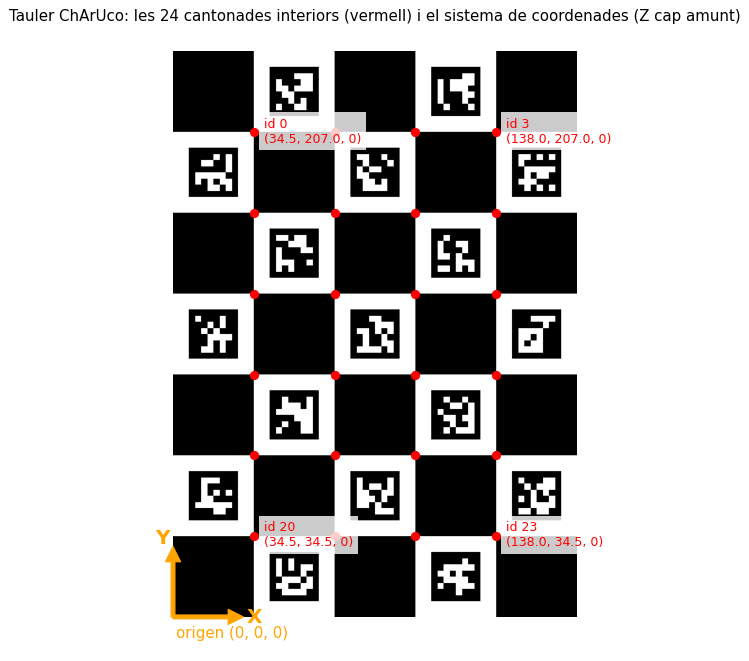

Coordenades de les primeres cantonades (mm):


,X,Y,Z
0,34.5,207.0,0.0
1,69.0,207.0,0.0
2,103.5,207.0,0.0
3,138.0,207.0,0.0
4,34.5,172.5,0.0
5,69.0,172.5,0.0


In [ ]:
SQUARES_X, SQUARES_Y = 5, 7
SQUARE_LENGTH_MM, MARKER_LENGTH_MM = 34.5, 21.0
ARUCO_DICTIONARY = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)

board = cv2.aruco.CharucoBoard((SQUARES_X, SQUARES_Y), SQUARE_LENGTH_MM, MARKER_LENGTH_MM, ARUCO_DICTIONARY)
charuco_detector = cv2.aruco.CharucoDetector(board)
BOARD_WIDTH_MM, BOARD_HEIGHT_MM = SQUARES_X * SQUARE_LENGTH_MM, SQUARES_Y * SQUARE_LENGTH_MM


def board_to_world(points):
    """OpenCV defines the board with Y pointing down the board and Z into the table.
    We flip Y (and therefore Z) so that the origin is the lower-left corner and Z points up."""
    points = np.array(points, dtype=np.float64).reshape(-1, 3).copy()
    points[:, 1] = BOARD_HEIGHT_MM - points[:, 1]
    points[:, 2] = -points[:, 2] + 0.0          # (+ 0.0 avoids printing -0.0)
    return points


corners_world = board_to_world(board.getChessboardCorners())   # the 24 inner corners, in mm

# Drawing of the board with its coordinate system
pixels_per_mm = 4
board_image = board.generateImage((int(BOARD_WIDTH_MM * pixels_per_mm), int(BOARD_HEIGHT_MM * pixels_per_mm)))
to_px = lambda p: (p[:, 0] * pixels_per_mm, (BOARD_HEIGHT_MM - p[:, 1]) * pixels_per_mm)

plt.figure(figsize=(7, 9))
plt.imshow(board_image, cmap='gray')
u, v = to_px(corners_world)
plt.scatter(u, v, c='red', s=40, zorder=3)
for corner_id in (0, 3, 20, 23):
    plt.annotate(f"id {corner_id}\n({corners_world[corner_id, 0]:.1f}, {corners_world[corner_id, 1]:.1f}, 0)",
                 (u[corner_id], v[corner_id]), xytext=(8, -8), textcoords='offset points', color='red', fontsize=10,
                 bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
origin_u, origin_v = to_px(np.zeros((1, 3)))
plt.annotate('', xy=(origin_u[0] + 120, origin_v[0]), xytext=(origin_u[0], origin_v[0]), arrowprops=dict(color='orange', width=3))
plt.annotate('', xy=(origin_u[0], origin_v[0] - 120), xytext=(origin_u[0], origin_v[0]), arrowprops=dict(color='orange', width=3))
plt.text(origin_u[0] + 125, origin_v[0] + 10, 'X', color='orange', fontsize=16, fontweight='bold')
plt.text(origin_u[0] - 30, origin_v[0] - 125, 'Y', color='orange', fontsize=16, fontweight='bold')
plt.text(origin_u[0] + 5, origin_v[0] + 35, 'origen (0, 0, 0)', color='orange', fontsize=12)
plt.title("Tauler ChArUco: les 24 cantonades interiors (vermell) i el sistema de coordenades (Z cap amunt)")
plt.xlim(-60, board_image.shape[1] + 60); plt.ylim(board_image.shape[0] + 60, -40); plt.axis('off'); plt.show()

print("Coordenades de les primeres cantonades (mm):")
display(pd.DataFrame(corners_world[:6], columns=['X', 'Y', 'Z']).round(1))

### 1.4.- Detectar el tauler en una foto

Per a cada foto, OpenCV:
1. Busca els marcadors ArUco i en llegeix el número.
2. A partir dels marcadors, localitza les cantonades interiors amb precisió subpíxel.
3. Ens dona, per a cada cantonada trobada, **el seu número** i **el seu píxel** $(u, v)$.

Amb el número sabem les seves coordenades 3D (taula anterior). Per tant, de cada foto obtenim parelles **punt 3D conegut ↔ píxel**: exactament el que necessita el camí 1.

Foto A: 17 marcadors i 24 cantonades detectades
Foto B: 17 marcadors i 24 cantonades detectades


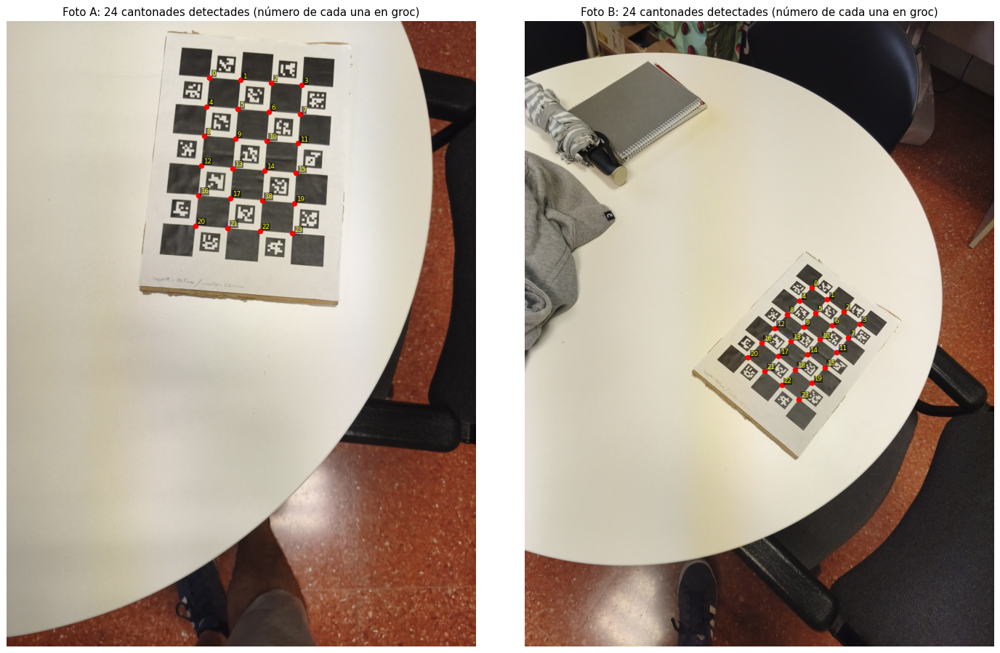


Versió d'OpenCV: 4.14.0


In [ ]:
MIN_CORNERS = 6

def detect_board(image_rgb, scales=(1.0, 0.5)):
    """Detects the ChArUco board. Tries the full image and, if needed, a downscaled copy.
    Returns (world points (N,3) in mm, pixels (N,2), corner ids, n_markers) or (None, n_markers)."""
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    best_markers = 0
    for scale in scales:
        image = gray if scale == 1.0 else cv2.resize(gray, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        charuco_corners, charuco_ids, marker_corners, marker_ids = charuco_detector.detectBoard(image)
        n_markers = 0 if marker_ids is None else len(marker_ids)
        best_markers = max(best_markers, n_markers)
        if charuco_ids is not None and len(charuco_ids) >= MIN_CORNERS:
            ids = charuco_ids.ravel()
            pixels = charuco_corners.reshape(-1, 2).astype(np.float64) / scale
            if scale != 1.0:   # refine the corners on the full-resolution image
                pixels = cv2.cornerSubPix(gray, pixels.astype(np.float32).reshape(-1, 1, 2), (11, 11), (-1, -1),
                                          (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 50, 0.01)).reshape(-1, 2).astype(np.float64)
            return corners_world[ids], pixels, ids, n_markers
    return None, best_markers


def draw_detection(image_rgb, detection, title, ax):
    _, pixels, ids, _ = detection
    ax.imshow(image_rgb)
    ax.scatter(pixels[:, 0], pixels[:, 1], s=25, c='red')
    for (u, v), corner_id in zip(pixels, ids):
        ax.text(u + 15, v - 15, str(corner_id), color='yellow', fontsize=7,
                bbox=dict(facecolor='black', alpha=0.5, pad=0.5, edgecolor='none'))
    ax.set_title(title); ax.axis('off')


table_detections = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 10))
for ax, (name, image) in zip(axes, table_images.items()):
    result = detect_board(image)
    if result[0] is None:
        print(f"Foto {name}: NO s'ha trobat el tauler ({result[1]} marcadors ArUco detectats).")
        print("   0 marcadors -> el diccionari o la mida del tauler no coincideixen, o el tauler surt massa petit/borrós.")
        print(f"   Pocs marcadors -> el tauler surt tallat, amb reflexos o massa inclinat.")
        ax.imshow(image); ax.set_title(f"Foto {name}: tauler NO detectat"); ax.axis('off')
        continue
    table_detections[name] = result
    print(f"Foto {name}: {result[3]} marcadors i {len(result[2])} cantonades detectades")
    draw_detection(image, result, f"Foto {name}: {len(result[2])} cantonades detectades (número de cada una en groc)", ax)
plt.tight_layout(); plt.show()

print("\nVersió d'OpenCV:", cv2.__version__)

### 1.5.- Els paràmetres interns de les càmeres A i B

Les fotos A i B s'han fet amb el mateix mòbil, en la mateixa orientació i sense zoom. Per tant, les dues càmeres tenen **els mateixos paràmetres interns**: la $K$ i la distorsió $\mathbf{d}$ del calibratge.

Calibrar la càmera vol dir conèixer aquests paràmetres. Amb ells podem, per exemple, **corregir la distorsió de la lent**: a la foto corregida, les rectes de l'escena tornen a ser rectes. La diferència és petita al centre de la imatge i més gran a les vores.

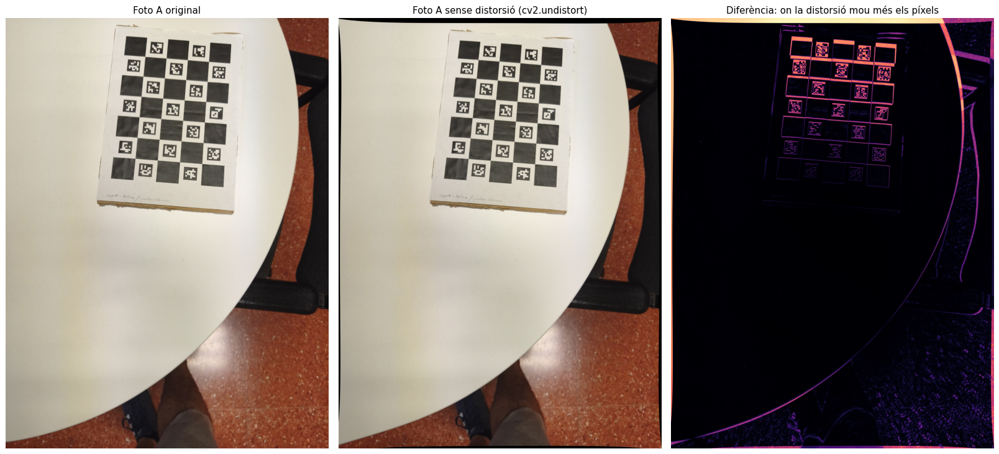

In [ ]:
camera_intrinsics = {name: (K, dist_coeffs) for name in table_images}   # same phone -> same K and d for A and B

undistorted_A = cv2.undistort(table_images['A'], K, dist_coeffs, None, K)
difference = cv2.absdiff(table_images['A'], undistorted_A).max(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(18, 8))
axes[0].imshow(table_images['A']); axes[0].set_title("Foto A original")
axes[1].imshow(undistorted_A); axes[1].set_title("Foto A sense distorsió (cv2.undistort)")
axes[2].imshow(difference, cmap='magma'); axes[2].set_title("Diferència: on la distorsió mou més els píxels")
for ax in axes:
    ax.axis('off')
plt.tight_layout(); plt.show()

### 1.6.- La resecció espacial: `cv2.solvePnP`

Ara la càmera ja està calibrada ($K$ i $\mathbf{d}$ coneguts) i volem la pose d'**una sola foto**. Per a cada cantonada detectada coneixem el seu punt 3D $(X, Y, Z)$ i el seu píxel $(u, v)$. L'equació de col·linealitat

$$\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \, R \begin{bmatrix} X - X_0 \\ Y - Y_0 \\ Z - Z_0 \end{bmatrix}$$

només té **6 incògnites**: la posició $(X_0, Y_0, Z_0)$ i els 3 angles de $R$. Cada cantonada dona **2 equacions** (una per a $u$ i una per a $v$; la tercera fila només serveix per eliminar $\lambda$). Amb les ~24 cantonades del tauler tenim ~48 equacions per a 6 incògnites.

**Què fa `cv2.solvePnP` per dins:**
1. Calcula una **primera aproximació** de la pose. Com que el tauler és pla, ho fa amb una homografia entre el tauler i la foto (com a les sessions d'homografia).
2. **Refina** la pose per mínims quadrats (mètode de Levenberg-Marquardt): va modificant els 6 paràmetres fins que la distància entre els píxels detectats i els píxels calculats amb l'equació és mínima.

**Què retorna:** `rvec` (el gir, en forma eix-angle) i `tvec`. Amb `cv2.Rodrigues(rvec)` obtenim la matriu $R$.

**Compte:** `tvec` **no és la posició de la càmera**. OpenCV escriu l'equació com $\lambda\,\mathbf{x} = K\,(R\,\mathbf{X} + \mathbf{t})$, i comparant-la amb la nostra surt $\mathbf{t} = -R\,\mathbf{X}_0$. Per tant:

$$\mathbf{X}_0 = -R^T \, \mathbf{t}$$

In [ ]:
def solve_pose(detection):
    object_points, pixels = detection[:2]          # 3D points (mm) and their pixels
    success, rvec, tvec = cv2.solvePnP(object_points, pixels, K, dist_coeffs, flags=cv2.SOLVEPNP_ITERATIVE)
    R = cv2.Rodrigues(rvec)[0]
    reprojected, _ = cv2.projectPoints(object_points, rvec, tvec, K, dist_coeffs)
    residuals = np.linalg.norm(reprojected.reshape(-1, 2) - pixels, axis=1)
    return dict(rvec=rvec.ravel(), tvec=tvec.ravel(), R=R, center=camera_center(R, tvec), residuals=residuals)


table_poses = {name: solve_pose(detection) for name, detection in table_detections.items()}

rows = []
for name, pose in table_poses.items():
    rows.append({'càmera': name, 'X0 (mm)': pose['center'][0], 'Y0 (mm)': pose['center'][1], 'Z0 (mm)': pose['center'][2],
                 'tvec (mm)': np.round(pose['tvec'], 1), 'rvec (rad)': np.round(pose['rvec'], 3),
                 'error mitjà (px)': pose['residuals'].mean()})
display(pd.DataFrame(rows).set_index('càmera').round(2))

baseline_mm = np.linalg.norm(table_poses['A']['center'] - table_poses['B']['center'])
print(f"Distància entre les càmeres A i B: {baseline_mm:.1f} mm")
print("Fixeu-vos que tvec i (X0, Y0, Z0) no s'assemblen: tvec és on és el tauler vist des de la càmera.")

,X0 (mm),Y0 (mm),Z0 (mm),tvec (mm),rvec (rad),error mitjà (px)
càmera,,,,,,
A,94.72,-138.09,431.44,"[-92.2, -80.0, 446.4]","[2.991, 0.115, 0.02]",0.76
B,141.24,-166.41,632.89,"[-76.1, 47.3, 663.4]","[2.555, 0.939, -0.042]",0.42


Distància entre les càmeres A i B: 208.7 mm
Fixeu-vos que tvec i (X0, Y0, Z0) no s'assemblen: tvec és on és el tauler vist des de la càmera.


### 1.7.- Els paràmetres de les càmeres A i B: interns i externs

`solvePnP` retorna la pose en el format d'OpenCV, que no és el de la fotogrametria:
* `rvec` **no són angles**: és el gir en forma eix-angle (la direcció del vector és l'eix de gir i la seva longitud, l'angle en radians).
* `tvec` **no és la posició**: és on és l'origen del tauler vist des de la càmera.

Per obtenir els paràmetres externs fotogramètrics:
* **Posició:** $\mathbf{X}_0 = -R^T \, \mathbf{t}$.
* **Angles** $\omega, \varphi, \kappa$: es descompon la matriu de rotació. Fem servir el conveni habitual en fotogrametria: eixos de la càmera amb $x$ a la dreta, $y$ amunt i $z$ cap enrere (la càmera mira cap a $-z$), i

$$R = R_x(\omega)\, R_y(\varphi)\, R_z(\kappa)$$


In [ ]:
def opencv_to_omega_phi_kappa(R_opencv):
    """OpenCV camera axes (x right, y down, z forward) -> photogrammetric axes (x right, y up, z backward),
    then R = Rx(omega)·Ry(phi)·Rz(kappa). Returns the three angles in degrees."""
    R = np.diag([1.0, -1.0, -1.0]) @ R_opencv
    return np.degrees([np.arctan2(-R[1, 2], R[2, 2]), np.arcsin(np.clip(R[0, 2], -1, 1)), np.arctan2(-R[0, 1], R[0, 0])])


def matrix_text(label, M, formats):
    """Matrix drawn with vertical bars, label on the middle row. 'formats' gives one format per column."""
    M = np.atleast_2d(M)
    lines = []
    for i, row in enumerate(M):
        cells = ''.join(fmt.format(v) for fmt, v in zip(formats, row))
        lines.append(f"{label if i == len(M) // 2 else ' ' * len(label)} │{cells} │")
    return '\n'.join(lines)


print("PARÀMETRES INTERNS (comuns a A i B)\n")
print(matrix_text('   K = ', K, ['{:9.1f}'] * 3))
print("\n   d = (k1, k2, p1, p2, k3) = (" + ', '.join(f'{v:.4f}' for v in dist_coeffs) + ")")

for name, pose in table_poses.items():
    omega, phi, kappa = opencv_to_omega_phi_kappa(pose['R'])
    X0, Y0, Z0 = pose['center']
    print("\n" + "─" * 60)
    print(f"PARÀMETRES EXTERNS DE LA CÀMERA {name}\n")
    print("   Format fotogramètric:")
    print(f"      X0 = {X0:.1f} mm    Y0 = {Y0:.1f} mm    Z0 = {Z0:.1f} mm")
    print(f"      ω = {omega:.2f}°    φ = {phi:.2f}°    κ = {kappa:.2f}°\n")
    print("   Format OpenCV (t en mm):\n")
    print(matrix_text('      [R | t] = ', np.hstack([pose['R'], pose['tvec'][:, None]]), ['{:9.4f}'] * 3 + ['  │{:8.1f}']))

PARÀMETRES INTERNS (comuns a A i B)

        │   2763.5      0.0   1574.0 │
   K =  │      0.0   2750.3   2020.7 │
        │      0.0      0.0      1.0 │

   d = (k1, k2, p1, p2, k3) = (0.0085, 0.1484, -0.0031, 0.0021, -0.1872)

────────────────────────────────────────────────────────────
PARÀMETRES EXTERNS DE LA CÀMERA A

   Format fotogramètric:
      X0 = 94.7 mm    Y0 = -138.1 mm    Z0 = 431.4 mm
      ω = -8.46°    φ = 1.09°    κ = -4.33°

   Format OpenCV (t en mm):

                 │   0.9970   0.0754   0.0190  │   -92.2 │
      [R | t] =  │   0.0774  -0.9861  -0.1471  │   -80.0 │
                 │   0.0076   0.1482  -0.9889  │   446.4 │

────────────────────────────────────────────────────────────
PARÀMETRES EXTERNS DE LA CÀMERA B

   Format fotogramètric:
      X0 = 141.2 mm    Y0 = -166.4 mm    Z0 = 632.9 mm
      ω = -23.23°    φ = 6.47°    κ = -39.04°

   Format OpenCV (t en mm):

                 │   0.7717   0.6259   0.1126  │   -76.1 │
      [R | t] =  │   0.6134  -0.6

### 1.8.- On eren les càmeres: vista 3D

Dibuixem el tauler (en el seu sistema de coordenades, en mm) i les dues càmeres a la posició $(X_0, Y_0, Z_0)$ que hem calculat. Cada càmera es dibuixa com una piràmide: el vèrtex és el centre òptic i la base és el pla de la imatge. La línia discontínua és **cap on mira** (l'eix $z$ de la càmera).

Gireu la vista amb el ratolí. Les càmeres haurien de ser **a sobre del tauler** ($Z_0 > 0$) i **mirant-lo**.

In [ ]:
def board_traces():
    """The board as a black-and-white mesh plus its 24 inner corners."""
    vertices, triangles, colors = [], [], []
    for column in range(SQUARES_X):
        for row in range(SQUARES_Y):
            x0, y0 = column * SQUARE_LENGTH_MM, BOARD_HEIGHT_MM - (row + 1) * SQUARE_LENGTH_MM
            n = len(vertices)
            vertices += [[x0, y0, 0], [x0 + SQUARE_LENGTH_MM, y0, 0], [x0 + SQUARE_LENGTH_MM, y0 + SQUARE_LENGTH_MM, 0], [x0, y0 + SQUARE_LENGTH_MM, 0]]
            triangles += [[n, n + 1, n + 2], [n, n + 2, n + 3]]
            colors += ['#222222' if (row + column) % 2 == 0 else '#f2f2f2'] * 2
    v, t = np.array(vertices), np.array(triangles)
    mesh = go.Mesh3d(x=v[:, 0], y=v[:, 1], z=v[:, 2], i=t[:, 0], j=t[:, 1], k=t[:, 2], facecolor=colors, name='tauler', hoverinfo='skip')
    axes = []
    for direction, color, label in (([1, 0, 0], 'red', 'X'), ([0, 1, 0], 'green', 'Y'), ([0, 0, 1], 'blue', 'Z')):
        end = np.array(direction) * 3 * SQUARE_LENGTH_MM
        axes.append(go.Scatter3d(x=[0, end[0]], y=[0, end[1]], z=[0, end[2]], mode='lines+text', text=['', label],
                                 line=dict(color=color, width=6), showlegend=False))
    return [mesh] + axes


traces = board_traces()
for (name, pose), color in zip(table_poses.items(), CAMERA_COLORS):
    label = f"{name} ({pose['center'][0]:.0f}, {pose['center'][1]:.0f}, {pose['center'][2]:.0f}) mm"
    traces += camera_traces(pose['R'], pose['center'], color, label, size=100)
centers = np.array([pose['center'] for pose in table_poses.values()])
traces.append(go.Scatter3d(x=centers[:, 0], y=centers[:, 1], z=centers[:, 2], mode='lines', line=dict(color='orange', width=5),
                           name=f'base A–B: {baseline_mm:.0f} mm'))
show_3d(traces, "Camí 1: posició i orientació de les càmeres A i B respecte del tauler (mm)")

### 1.9.- El calibratge ja havia calculat les poses

Recordeu que `cv2.calibrateCamera` calcula **alhora** els paràmetres interns i **la pose de cada foto del calibratge**. Dibuixem-les totes, juntament amb les càmeres A i B.

Les poses del fitxer de calibratge estan en el sistema del tauler d'OpenCV ($Y$ cap avall del tauler, $Z$ cap a dins de la taula). Primer les passem al nostre sistema (origen a la cantonada inferior esquerra, $Z$ cap amunt).

Això mostra que calibrar i calcular la pose són **el mateix problema** (l'equació de col·linealitat), però amb incògnites diferents:

| | Calibratge (`calibrateCamera`) | Resecció (`solvePnP`) |
|---|---|---|
| Incògnites | Interns (9) + pose de cada foto (6 per foto) | Només la pose (6) |
| Fotos necessàries | Moltes | **Una** |
| Quan es fa | Un cop per càmera | Cada vegada que volem situar una foto |

En un projecte real, la càmera es calibra una vegada i després es calcula la pose de cada foto nova. Per això cal conèixer `solvePnP` encara que el calibratge també doni poses.

In [ ]:
# OpenCV board frame -> our frame: (x, y, z) -> (x, H - y, -z)
flip, offset = np.diag([1.0, -1.0, -1.0]), np.array([0.0, BOARD_HEIGHT_MM, 0.0])
calibration_poses = []
for rvec, tvec in zip(calibration_rvecs, calibration_tvecs):
    R = cv2.Rodrigues(rvec)[0] @ flip
    calibration_poses.append((R, tvec - R @ offset))

traces = board_traces()
for index, (R, t) in enumerate(calibration_poses):
    traces += camera_traces(R, camera_center(R, t), '#7f7f7f', 'fotos del calibratge', size=40,
                            label=False, legend=(index == 0))
for (name, pose), color in zip(table_poses.items(), CAMERA_COLORS):
    traces += camera_traces(pose['R'], pose['center'], color, name, size=70)
show_3d(traces, f"Les {len(calibration_poses)} poses del calibratge (gris) i les càmeres A i B (color)", height=700)

DEEEURES "FACILS"

# PART 2 — Camí 2: la pose a partir de dues fotos i punts homòlegs

Ara no coneixem **cap** punt de l'escena: només dues fotos de l'aula. La cadena és:

$$\text{homòlegs} \;\xrightarrow{\;\texttt{findEssentialMat}\; (\text{RANSAC})\;}\; E \;\xrightarrow{\;\texttt{recoverPose}\;}\; R, \; \mathbf{t}$$

No cal calcular la matriu fonamental $F$: com que coneixem $K$, es calcula directament $E$.

### 2.1.- Les fotos de l'aula

Dues fotos de l'aula fetes des de dos llocs diferents (càmeres A i B), amb el mateix mòbil. A l'escena **no hi ha cap punt de coordenades conegudes**: només tenim les dues fotos.

Falten aquests fitxers: ['aula_A.jpg', 'aula_B.jpg'] -> puja'ls ara


Saving aula_A.jpg to aula_A.jpg
Saving aula_B.jpg to aula_B.jpg


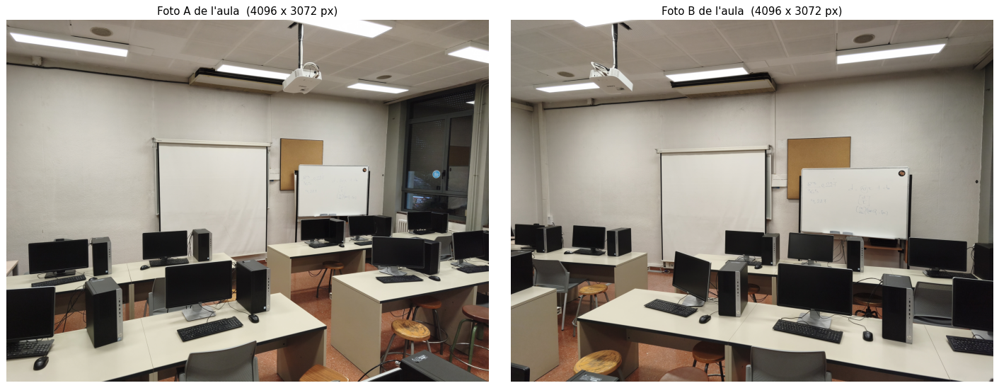

In [ ]:
CLASSROOM_A_PATH, CLASSROOM_B_PATH = 'aula_A.jpg', 'aula_B.jpg'

missing_files = [p for p in (CLASSROOM_A_PATH, CLASSROOM_B_PATH) if not os.path.exists(p)]
if missing_files and IN_COLAB:
    print("Falten aquests fitxers:", missing_files, "-> puja'ls ara")
    files.upload()

classroom_A, classroom_B = load_rgb(CLASSROOM_A_PATH), load_rgb(CLASSROOM_B_PATH)
classroom_height, classroom_width = classroom_A.shape[:2]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, image, name in zip(axes, (classroom_A, classroom_B), ('A', 'B')):
    ax.imshow(image); ax.set_title(f"Foto {name} de l'aula  ({image.shape[1]} x {image.shape[0]} px)"); ax.axis('off')
plt.tight_layout(); plt.show()

### 2.2.- Els paràmetres interns per a fotos horitzontals

Les fotos de l'aula són **horitzontals** (4096 × 3072) i el calibratge es va fer amb fotos **verticals** (3072 × 4096). Girar el mòbil 90° gira també els eixos de la imatge, i els paràmetres interns s'han d'adaptar:
* les focals s'intercanvien: $f_x \leftrightarrow f_y$;
* el punt principal passa a $(c_y,\; W_{vertical} - 1 - c_x)$;
* els coeficients de distorsió tangencial ($p_1, p_2$) també giren. La radial ($k_1, k_2, k_3$) no canvia, perquè només depèn de la distància al centre.

In [ ]:
def rotate_calibration_to_landscape(camera_matrix, distortion, portrait_width):
    """Portrait calibration -> landscape calibration (u_land = v_port, v_land = W_port - 1 - u_port)."""
    fx, fy, cx, cy = camera_matrix[0, 0], camera_matrix[1, 1], camera_matrix[0, 2], camera_matrix[1, 2]
    k1, k2, p1, p2, k3 = distortion
    landscape_matrix = np.array([[fy, 0, cy], [0, fx, (portrait_width - 1) - cx], [0, 0, 1.0]])
    return landscape_matrix, np.array([k1, k2, -p2, p1, k3])


calibration_width, calibration_height = calibration_size
if (calibration_height > calibration_width) != (classroom_height > classroom_width):
    K_classroom, dist_classroom = rotate_calibration_to_landscape(K, dist_coeffs, calibration_width)
    print("Les fotos tenen una orientació diferent de la del calibratge: giro K i la distorsió.\n")
else:
    K_classroom, dist_classroom = K.copy(), dist_coeffs.copy()
    print("Les fotos tenen la mateixa orientació que el calibratge: K no canvia.\n")

print(matrix_text('   K vertical (calibratge) = ', K, ['{:9.1f}'] * 3))
print()
print(matrix_text('   K horitzontal (aula)    = ', K_classroom, ['{:9.1f}'] * 3))
print("\n   d vertical    =", dist_coeffs.round(4))
print("   d horitzontal =", dist_classroom.round(4))

Les fotos tenen una orientació diferent de la del calibratge: giro K i la distorsió.

                              │   2763.5      0.0   1574.0 │
   K vertical (calibratge) =  │      0.0   2750.3   2020.7 │
                              │      0.0      0.0      1.0 │

                              │   2750.3      0.0   2020.7 │
   K horitzontal (aula)    =  │      0.0   2763.5   1497.0 │
                              │      0.0      0.0      1.0 │

   d vertical    = [ 0.0085  0.1484 -0.0031  0.0021 -0.1872]
   d horitzontal = [ 0.0085  0.1484 -0.0021 -0.0031 -0.1872]


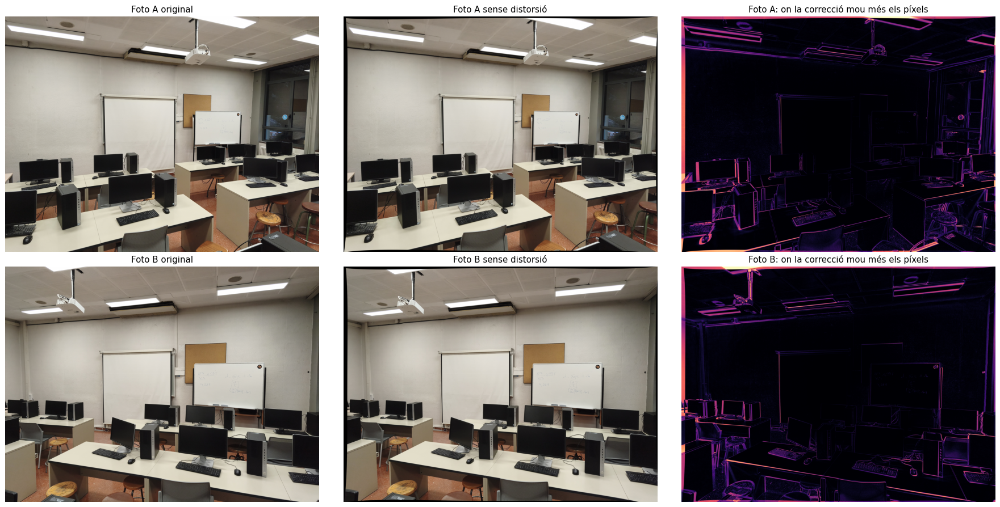

In [ ]:
classroom_undistorted = {name: cv2.undistort(image, K_classroom, dist_classroom, None, K_classroom)
                         for name, image in (('A', classroom_A), ('B', classroom_B))}

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for row, (name, image) in enumerate((('A', classroom_A), ('B', classroom_B))):
    corrected = classroom_undistorted[name]
    difference = cv2.absdiff(image, corrected).max(axis=2)
    axes[row, 0].imshow(image); axes[row, 0].set_title(f"Foto {name} original")
    axes[row, 1].imshow(corrected); axes[row, 1].set_title(f"Foto {name} sense distorsió")
    axes[row, 2].imshow(difference, cmap='magma'); axes[row, 2].set_title(f"Foto {name}: on la correcció mou més els píxels")
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout(); plt.show()

### 2.3.- Punts homòlegs amb SuperPoint + LightGlue

Entre aquestes dues fotos la càmera ha girat molt i hi ha molts objectes repetits (monitors, teclats, cadires). Els detectors clàssics com SIFT hi troben molt poques parelles correctes. Fem servir **SuperPoint** (detector i descriptor amb xarxes neuronals) + **LightGlue** (emparellament amb xarxes neuronals), que és molt més robust en canvis de punt de vista grans.

* Les xarxes treballen sobre una còpia de la foto reduïda a 1600 px, i retornen els píxels en la mida original.
* La primera execució descarrega els pesos de les xarxes (uns segons). Funciona sense GPU.

In [ ]:
try:
    import lightglue
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'git+https://github.com/cvg/LightGlue.git'], check=True)

import torch
from lightglue import LightGlue, SuperPoint
from lightglue.utils import load_image, rbd

torch.set_grad_enabled(False)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
feature_extractor = SuperPoint(max_num_keypoints=4096).eval().to(device)
feature_matcher = LightGlue(features='superpoint').eval().to(device)

def match_superpoint_lightglue(path_1, path_2, resize=1600):
    features_1 = feature_extractor.extract(load_image(path_1).to(device), resize=resize)
    features_2 = feature_extractor.extract(load_image(path_2).to(device), resize=resize)
    matches = rbd(feature_matcher({'image0': features_1, 'image1': features_2}))['matches']
    features_1, features_2 = rbd(features_1), rbd(features_2)
    points_1 = features_1['keypoints'][matches[:, 0]].cpu().numpy().astype(np.float64)
    points_2 = features_2['keypoints'][matches[:, 1]].cpu().numpy().astype(np.float64)
    return points_1, points_2

for name, image in classroom_undistorted.items():
    cv2.imwrite(f'aula_{name}_undistorted.jpg', cv2.cvtColor(image, cv2.COLOR_RGB2BGR))
matches_A, matches_B = match_superpoint_lightglue('aula_A_undistorted.jpg', 'aula_B_undistorted.jpg')
print(f"Parelles d'homòlegs trobades per LightGlue: {len(matches_A)}")

Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /root/.cache/torch/hub/checkpoints/superpoint_v1.pth


100%|██████████| 4.96M/4.96M [00:00<00:00, 70.4MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /root/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:00<00:00, 139MB/s]


Parelles d'homòlegs trobades per LightGlue: 621


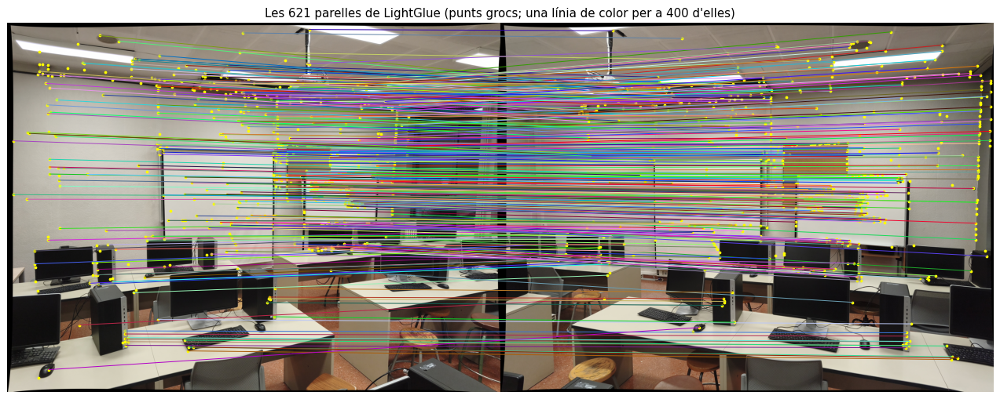

In [ ]:
def draw_pairs(image_1, image_2, points_1, points_2, title, mask=None, max_lines=400):
    """Side-by-side photos with the pairs joined by lines.
    Without mask: every pair in a different colour. With mask: green = accepted, red = rejected."""
    rng = np.random.default_rng(RANDOM_SEED)
    width = image_1.shape[1]
    plt.figure(figsize=(18, 7)); plt.imshow(np.hstack([image_1, image_2]))
    groups = [(np.ones(len(points_1), bool), None, None)] if mask is None else [(~mask, 'red', 'rebutjades'), (mask, 'lime', 'correctes')]
    for keep, color, label in groups:
        indices = np.flatnonzero(keep)
        plt.scatter(points_1[indices, 0], points_1[indices, 1], s=4, c=color or 'yellow')
        plt.scatter(points_2[indices, 0] + width, points_2[indices, 1], s=4, c=color or 'yellow')
        for k in rng.choice(indices, min(max_lines, len(indices)), replace=False):
            plt.plot([points_1[k, 0], points_2[k, 0] + width], [points_1[k, 1], points_2[k, 1]], '-', lw=0.8,
                     color=color or rng.random(3))
        if label:
            plt.plot([], [], color=color, label=f"{label}: {keep.sum()}")
    if mask is not None:
        plt.legend(loc='lower right', fontsize=12)
    plt.title(title); plt.axis('off'); plt.show()


draw_pairs(classroom_undistorted['A'], classroom_undistorted['B'], matches_A, matches_B,
           f"Les {len(matches_A)} parelles de LightGlue (punts grocs; una línia de color per a {min(400, len(matches_A))} d'elles)")

### 2.4.- La matriu essencial amb RANSAC: `cv2.findEssentialMat`

Per a cada parella d'homòlegs, el raig de la càmera A, el raig de la càmera B i la base són al mateix pla (**coplanarietat**). Escrit amb matrius:

$$\mathbf{x}_B^T \, E \, \mathbf{x}_A = 0, \qquad E = [\mathbf{t}]_\times \, R$$

on $\mathbf{x}_A, \mathbf{x}_B$ són els píxels convertits en direccions de raig amb $K$. Cada parella dona **una equació**, i $E$ té 5 graus de llibertat (3 del gir + 2 de la direcció de la base).

**Què fa `cv2.findEssentialMat` per dins:**
1. Converteix els píxels en raigs amb $K^{-1}$.
2. **RANSAC:** agafa 5 parelles a l'atzar, calcula $E$ amb l'algorisme dels 5 punts i compta quantes parelles la compleixen (distància a la recta epipolar menor que `threshold` píxels). Ho repeteix moltes vegades i es queda amb la $E$ que en compleix més.
3. Retorna $E$ i la **màscara** de parelles correctes (inliers).

El llindar és de 2 px perquè les xarxes treballen a 1600 px: un error d'1 px a la foto reduïda són ~2,5 px a la foto original.

Parelles correctes (inliers): 300 de 621  (48 %)

E =
 [[-0.0103  0.1905  0.0257]
 [ 0.2997  0.0211 -0.6397]
 [-0.0008  0.6806  0.0152]]


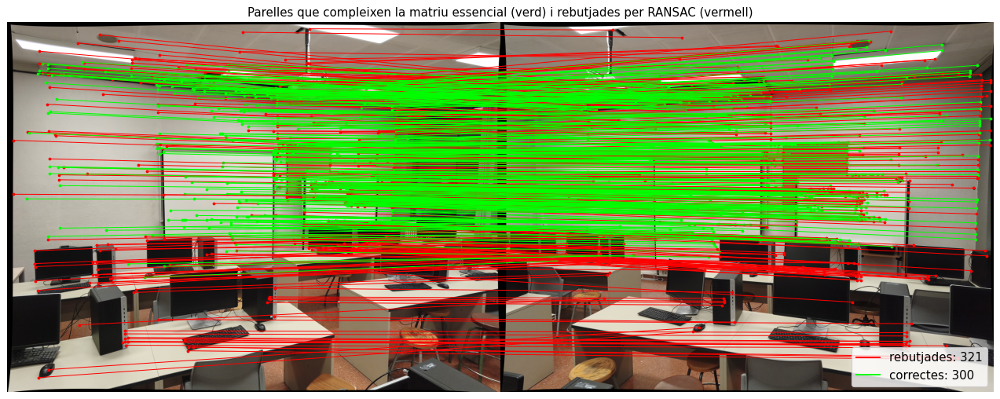

In [ ]:
RANSAC_THRESHOLD_PX = 2.0

points_A, points_B = matches_A, matches_B          # already undistorted: LightGlue worked on the undistorted photos

cv2.setRNGSeed(RANDOM_SEED)
E, inlier_mask = cv2.findEssentialMat(points_A, points_B, K_classroom, method=cv2.RANSAC, prob=0.999, threshold=RANSAC_THRESHOLD_PX)
is_inlier = inlier_mask.ravel().astype(bool)
inliers_A, inliers_B = points_A[is_inlier], points_B[is_inlier]

print(f"Parelles correctes (inliers): {is_inlier.sum()} de {len(is_inlier)}  ({100 * is_inlier.mean():.0f} %)")
print("\nE =\n", E)

draw_pairs(classroom_undistorted['A'], classroom_undistorted['B'], matches_A, matches_B,
           "Parelles que compleixen la matriu essencial (verd) i rebutjades per RANSAC (vermell)", mask=is_inlier)

### 2.5.- De $E$ a la pose: `cv2.recoverPose`

`cv2.recoverPose` descompon $E$ i retorna el gir $R$ i la base $\mathbf{t}$ de la càmera B. Fa servir només les parelles correctes (la màscara de RANSAC).

Mostrem els paràmetres amb els mateixos dos formats que a la Part 1, amb una diferència important: al camí 2 **no hi ha sistema del tauler**. El sistema de referència és **la càmera A**:
* A és a l'origen i sense gir: $\mathbf{X}_0^A = (0, 0, 0)$, $R_A = I$.
* Els eixos són els de la càmera A: $x$ a la dreta, $y$ avall, $z$ endavant. Un punt passa de coordenades d'A a coordenades de B amb $\mathbf{X}_B = R\,\mathbf{X}_A + \mathbf{t}$, i el centre de B és $\mathbf{X}_0^B = -R^T \mathbf{t}$.
* Els angles de B són els girs respecte d'aquests eixos ($R = R_x(\omega)\,R_y(\varphi)\,R_z(\kappa)$): $\omega$ al voltant de l'eix dreta (mirar amunt/avall), $\varphi$ al voltant de l'eix vertical (mirar a esquerra/dreta) i $\kappa$ al voltant de l'eix on mira (inclinar la foto).
* $\mathbf{t}$ té **longitud 1**: sabem cap on és B, però **no a quants metres**. Les posicions no tenen unitats.

In [ ]:
n_in_front, R_B, t_B, pose_mask = cv2.recoverPose(E, points_A, points_B, K_classroom, mask=inlier_mask.copy())
t_B = t_B.ravel()
center_B = camera_center(R_B, t_B)


def rotation_to_angles(R):
    """R = Rx(omega)·Ry(phi)·Rz(kappa), angles in degrees, in the axes of camera A (x right, y down, z forward)."""
    return np.degrees([np.arctan2(-R[1, 2], R[2, 2]), np.arcsin(np.clip(R[0, 2], -1, 1)), np.arctan2(-R[0, 1], R[0, 0])])


print("PARÀMETRES INTERNS (comuns a A i B, fotos horitzontals)\n")
print(matrix_text('   K = ', K_classroom, ['{:9.1f}'] * 3))
print("\n   d = (k1, k2, p1, p2, k3) = (" + ', '.join(f'{v:.4f}' for v in dist_classroom) + ")")

classroom_poses = {'A': (np.eye(3), np.zeros(3)), 'B': (R_B, t_B)}
for name, (R, t) in classroom_poses.items():
    omega, phi, kappa = rotation_to_angles(R)
    X0, Y0, Z0 = camera_center(R, t)
    print("\n" + "─" * 60)
    print(f"PARÀMETRES EXTERNS DE LA CÀMERA {name}" + ("   (origen del sistema, per definició)" if name == 'A' else "") + "\n")
    print("   Format fotogramètric (posició en unitats de base):")
    print(f"      X0 = {X0:+.3f}    Y0 = {Y0:+.3f}    Z0 = {Z0:+.3f}")
    print(f"      ω = {omega:.2f}°    φ = {phi:.2f}°    κ = {kappa:.2f}°\n")
    print("   Format OpenCV (t en unitats de base):\n")
    print(matrix_text('      [R | t] = ', np.hstack([R, t[:, None]]), ['{:9.4f}'] * 3 + ['  │{:8.3f}']))

print("\n" + "─" * 60)
print(f"Distància A–B: {np.linalg.norm(center_B):.3f}  ← sempre 1: el camí 2 no dona l'escala")
print(f"B és {abs(center_B[0]):.2f} {'a la dreta' if center_B[0] > 0 else "a l'esquerra"} i {abs(center_B[2]):.2f} "
      f"{'endavant' if center_B[2] > 0 else 'enrere'} d'A, i està girada {rotation_angle_deg(R_B):.1f}° en total")

PARÀMETRES INTERNS (comuns a A i B, fotos horitzontals)

        │   2750.3      0.0   2020.7 │
   K =  │      0.0   2763.5   1497.0 │
        │      0.0      0.0      1.0 │

   d = (k1, k2, p1, p2, k3) = (0.0085, 0.1484, -0.0021, -0.0031, -0.1872)

────────────────────────────────────────────────────────────
PARÀMETRES EXTERNS DE LA CÀMERA A   (origen del sistema, per definició)

   Format fotogramètric (posició en unitats de base):
      X0 = +0.000    Y0 = +0.000    Z0 = +0.000
      ω = -0.00°    φ = 0.00°    κ = -0.00°

   Format OpenCV (t en unitats de base):

                 │   1.0000   0.0000   0.0000  │   0.000 │
      [R | t] =  │   0.0000   1.0000   0.0000  │   0.000 │
                 │   0.0000   0.0000   1.0000  │   0.000 │

────────────────────────────────────────────────────────────
PARÀMETRES EXTERNS DE LA CÀMERA B

   Format fotogramètric (posició en unitats de base):
      X0 = +0.906    Y0 = -0.008    Z0 = +0.424
      ω = -3.34°    φ = 40.68°    κ = 3.57°

   For

### 2.6.- Vista 3D: les dues càmeres i els punts de l'aula

Amb la pose de les dues càmeres podem **triangular** els homòlegs: per a cada parella, el punt 3D on es tallen els dos raigs (`cv2.triangulatePoints`). La triangulació la veurem a fons més endavant; aquí només la fem servir per **veure** l'escena.

* Les matrius de projecció són $P_A = K\,[I \,|\, \mathbf{0}]$ i $P_B = K\,[R \,|\, \mathbf{t}]$.
* Tot està en **unitats de base**: la distància entre A i B val 1. Si la base real fos de 80 cm, caldria multiplicar totes les distàncies per 0,8 m.
* Per visualitzar-ho amb l'eix vertical cap amunt, dibuixem $(x, z, -y)$ del sistema de la càmera A.

In [ ]:
def triangulate(K_matrix, R, t, points_1, points_2):
    P1 = K_matrix @ np.hstack([np.eye(3), np.zeros((3, 1))])
    P2 = K_matrix @ np.hstack([R, t.reshape(3, 1)])
    homogeneous = cv2.triangulatePoints(P1, P2, points_1.T, points_2.T)
    return (homogeneous[:3] / homogeneous[3]).T


camera_A_frame_to_display = lambda p: np.column_stack([p[:, 0], p[:, 2], -p[:, 1]])

good_A, good_B = points_A[pose_mask.ravel() > 0], points_B[pose_mask.ravel() > 0]
points_3d = triangulate(K_classroom, R_B, t_B, good_A, good_B)
pixel_colors = classroom_A[np.clip(good_A[:, 1].astype(int), 0, classroom_height - 1), np.clip(good_A[:, 0].astype(int), 0, classroom_width - 1)]

keep = points_3d[:, 2] < np.percentile(points_3d[:, 2], 98)          # hide a few far outliers
shown = camera_A_frame_to_display(points_3d[keep])
traces = [go.Scatter3d(x=shown[:, 0], y=shown[:, 1], z=shown[:, 2], mode='markers', name='punts triangulats',
                       marker=dict(size=3, color=[f'rgb({r},{g},{b})' for r, g, b in pixel_colors[keep]]))]
traces += camera_traces(np.eye(3), np.zeros(3), CAMERA_COLORS[0], 'A (origen)', size=0.25, to_display=camera_A_frame_to_display)
traces += camera_traces(R_B, center_B, CAMERA_COLORS[1], 'B', size=0.25, to_display=camera_A_frame_to_display)
base_line = camera_A_frame_to_display(np.vstack([np.zeros(3), center_B]))
traces.append(go.Scatter3d(x=base_line[:, 0], y=base_line[:, 1], z=base_line[:, 2], mode='lines', line=dict(color='orange', width=6), name='base (longitud 1)'))
show_3d(traces, "Camí 2: càmeres A i B i punts de l'aula (unitats de base)", eye=(-1.2, -1.8, 0.9),
        axis_titles=('x (dreta)', 'z (endavant)', '−y (amunt)'))
print(f"Profunditat dels punts: mediana {np.median(points_3d[:, 2]):.1f} unitats de base")

Profunditat dels punts: mediana 1.5 unitats de base


### 2.7.- Què fa `recoverPose` per dins: les quatre solucions de $E$

$E = [\mathbf{t}]_\times R$ només imposa que els dos raigs i la base siguin al mateix pla. Això també es compleix si **invertim la base** o si **girem B mitja volta** al voltant de la base: d'una $E$ en surten **4 combinacions** (R, t), que dona `cv2.decomposeEssentialMat`.

Per triar-ne una, `recoverPose` triangula les parelles correctes amb cada combinació i mira la **profunditat** de cada punt a les dues càmeres. Una càmera no pot veure un punt que té al darrere: només la solució correcta deixa els punts **davant de les dues càmeres** (test de quiralitat).

In [ ]:
R1, R2, t_candidate = cv2.decomposeEssentialMat(E)
t_candidate = t_candidate.ravel()
candidates = {'(a) R1, +t': (R1, t_candidate), '(b) R1, −t': (R1, -t_candidate),
              '(c) R2, +t': (R2, t_candidate), '(d) R2, −t': (R2, -t_candidate)}

solutions = {}
for label, (R, t) in candidates.items():
    points = triangulate(K_classroom, R, t, inliers_A, inliers_B)
    depth_A, depth_B = points[:, 2], (points @ R.T + t)[:, 2]
    solutions[label] = dict(R=R, t=t, points=points, in_front=(depth_A > 0) & (depth_B > 0))

summary = pd.DataFrame({label: {'gir de B (°)': rotation_angle_deg(s['R']), 't': s['t'].round(3),
                                '% davant de les dues càmeres': 100 * s['in_front'].mean()}
                        for label, s in solutions.items()}).T
display(summary)
winner = max(solutions, key=lambda label: solutions[label]['in_front'].sum())
same = rotation_angle_deg(solutions[winner]['R'] @ R_B.T) < 1e-6 and np.allclose(solutions[winner]['t'], t_B, atol=1e-6)
print(f"Solució guanyadora: {winner}   ·   coincideix amb la de recoverPose: {'sí' if same else 'no'}")

,gir de B (°),t,% davant de les dues càmeres
"(a) R1, +t",178.877191,"[-0.962, -0.032, 0.27]",0.0
"(b) R1, −t",178.877191,"[0.962, 0.032, -0.27]",0.0
"(c) R2, +t",40.855007,"[-0.962, -0.032, 0.27]",100.0
"(d) R2, −t",40.855007,"[0.962, 0.032, -0.27]",0.0


Solució guanyadora: (c) R2, +t   ·   coincideix amb la de recoverPose: sí


Les quatre solucions vistes des de dalt: **verd** si el punt és davant de les dues càmeres, **vermell** si és darrere d'alguna. Les línies discontínues indiquen cap on mira cada càmera.

In [ ]:
labels = list(solutions)
VIEW_LIMIT = np.array([1.6, 2.0, 1.0])                              # half-size of the drawn box (x, forward, up), in base units
figure = make_subplots(rows=2, cols=2, specs=[[{'type': 'scene'}] * 2] * 2,
                       subplot_titles=[f"{label}: {100 * solutions[label]['in_front'].mean():.0f} % davant" + ('  ✔' if label == winner else '')
                                       for label in labels], horizontal_spacing=0.02, vertical_spacing=0.06)
for index, label in enumerate(labels):
    solution = solutions[label]
    row, col = index // 2 + 1, index % 2 + 1
    shown = camera_A_frame_to_display(solution['points'])
    near = np.all(np.abs(shown) < VIEW_LIMIT, axis=1)               # keep the points inside the drawn box
    shown, colors = shown[near], np.where(solution['in_front'][near], 'green', 'red')
    figure.add_trace(go.Scatter3d(x=shown[:, 0], y=shown[:, 1], z=shown[:, 2], mode='markers', marker=dict(size=2, color=colors),
                                  showlegend=False), row=row, col=col)
    for trace in camera_traces(np.eye(3), np.zeros(3), CAMERA_COLORS[0], 'A', size=0.3, to_display=camera_A_frame_to_display) + \
                 camera_traces(solution['R'], camera_center(solution['R'], solution['t']), CAMERA_COLORS[1], 'B', size=0.3,
                               to_display=camera_A_frame_to_display):
        trace.showlegend = False
        figure.add_trace(trace, row=row, col=col)
camera_view = dict(eye=dict(x=0.2, y=-0.4, z=2.2), up=dict(x=0, y=1, z=0))
figure.update_scenes(camera=camera_view, xaxis_title='x (dreta)', yaxis_title='z (endavant)', zaxis_title='amunt',
                     xaxis_range=[-VIEW_LIMIT[0], VIEW_LIMIT[0]], yaxis_range=[-VIEW_LIMIT[1], VIEW_LIMIT[1]],
                     zaxis_range=[-VIEW_LIMIT[2], VIEW_LIMIT[2]], aspectmode='manual',
                     aspectratio=dict(x=VIEW_LIMIT[0], y=VIEW_LIMIT[1], z=VIEW_LIMIT[2]))
figure.update_layout(height=900, title="Les 4 solucions de E (vistes des de dalt). Verd: davant de les dues càmeres · vermell: darrere d'alguna",
                     margin=dict(l=0, r=0, t=70, b=0))
figure.show()